# Задача 7: Методи регресійного аналізу в Python

Загальна мета полягає в тому, щоб пояснити ціни продажу SalePrice за допомогою набору змінних, використовуючи набір даних із попереднього домашнього завдання (Ames Housing). Змінна SalePrice приймається як залежна змінна (target), а решта змінних – як пояснювальні (features).

***Answer***

Виконуємо обов'язкові пункти (а), (в)–(ж), (і), (к) за [умовою](../input/assignment_4.pdf). Пункти (б), (з), (и) опціональні й залишені невиконаними.

Дані та їх підготовка такі самі, як у частині (1): повний Ames Housing, `SalePrice` у доларах США; `Order`, `PID`, `GarageYrBlt` вилучено. `MSSubClass` кодується як категорія, `OverallQual` та `OverallCond` залишаються порядковими числами. Структурне `NA` збережено, числові пропуски заповнюємо навчальною медіаною, категоріальні рівнем `Missing`. Даммі мають шкалу 0/1, числові ознаки стандартизовано для узгодженого порівняння з лінійними моделями. Деревам стандартизація не потрібна, але додатне лінійне перетворення зберігає порядок значень.

Використовуємо те саме випадкове розбиття 80/20 із seed 42. Відкладені 20% тут називаємо валідаційною вибіркою: за умовою багаторазово розглядаємо її помилки. Це не нова незалежна тестова вибірка. Підготовка навчається тільки на навчальній частині.

Ноутбук запускається самостійно. У (ж) заново відтворюємо Lasso через ту саму 5-блочну крос-валідацію повного pipeline та OLS на тій самій матриці. Ансамблі будуються з глибоких дерев; випадковий ліс розглядає третину закодованих ознак у кожному вузлі. Кількість дерев для фінального порівняння заздалегідь фіксуємо на 200.

In [1]:
# Імпорти та спільні налаштування.
# ========= YOUR CODE STARTS HERE ========= #
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor

TASK_DIR = Path.cwd()
if (TASK_DIR / "labs" / "task4").is_dir():
    TASK_DIR = TASK_DIR / "labs" / "task4"
elif TASK_DIR.name == "notebooks":
    TASK_DIR = TASK_DIR.parent
DATA_PATH = TASK_DIR.parent / "task3" / "input" / "AmesHousing.txt"
FIGURES_DIR = TASK_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
SEED = 42
FINAL_TREES = 200
pd.set_option("display.max_rows", 350)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:.6g}".format)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
# Невідомі категорії кодуються нулями; нижче показано їх кількості.
warnings.filterwarnings("ignore", message="Found unknown categories in columns.*",
                        category=UserWarning, module="sklearn.preprocessing._encoders")

In [2]:
# Завантаження та підготовка даних.
# ========= YOUR CODE STARTS HERE ========= #
df = pd.read_csv(DATA_PATH, sep="\t", keep_default_na=False, na_values=[""])
df.columns = df.columns.str.replace(" ", "").str.replace("/", "")
for column in df.select_dtypes(exclude="number").columns:
    df[column] = df[column].str.strip()
df["MSSubClass"] = df["MSSubClass"].astype(str)
X = df.drop(columns=["SalePrice", "Order", "PID", "GarageYrBlt"])
y = df["SalePrice"]
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(exclude="number").columns.tolist()
display(pd.Series({
    "Спостережень": len(df), "Навчальна частина": len(X_train),
    "Валідаційна частина": len(X_valid), "Числових ознак": len(numeric_columns),
    "Категоріальних ознак": len(categorical_columns),
    "Пропусків у SalePrice": y.isna().sum(),
}).to_frame("Значення"))
display(df["FireplaceQu"].value_counts(dropna=False).rename_axis("FireplaceQu").to_frame("Кількість"))


# Кожне перетворення навчається лише на переданій навчальній частині.
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_columns),
    ("cat", categorical_pipe, categorical_columns),
], verbose_feature_names_out=False)
prepared = clone(preprocessor).fit(X_train)
Z_train = prepared.transform(X_train)
Z_valid = prepared.transform(X_valid)
feature_names = prepared.get_feature_names_out()

print("Закодована навчальна матриця:", Z_train.shape)
encoder = prepared.named_transformers_["cat"].named_steps["encode"]
unknown_counts = {column: (~X_valid[column].fillna("Missing").isin(categories)).sum()
                  for column, categories in zip(categorical_columns, encoder.categories_)}
display(pd.Series(unknown_counts, name="Невідомих значень у валідації")
        .loc[lambda s: s > 0].rename_axis("Ознака").to_frame())
assert np.isfinite(Z_train).all() and np.isfinite(Z_valid).all()

,Значення
Спостережень,2930
Навчальна частина,2344
Валідаційна частина,586
Числових ознак,34
Категоріальних ознак,44
Пропусків у SalePrice,0


,Кількість
FireplaceQu,
NA,1422
Gd,744
TA,600
Fa,75
Po,46
Ex,43


Закодована навчальна матриця: (2344, 294)


,Невідомих значень у валідації
Ознака,
Exterior2nd,1
Electrical,1
KitchenQual,1
MiscFeature,1


## (2)

На наступному кроці ми моделюємо SalePrice за допомогою дерев регресії, використовуючи DecisionTreeRegressor з бібліотеки sklearn.tree.

### (а)

Нехай GrLivArea буде першою змінною, яка використовується для розщеплення (splitting). Запишіть відповідну задачу оптимізації (мінімізацію суми квадратів залишків RSS для двох дочірніх вузлів) та поясніть, як працює алгоритм жадібного пошуку точки розщеплення.

In [3]:
# ========= YOUR CODE STARTS HERE ========= #
# Теоретичне формулювання наведено нижче.

***Answer***

Для першого розщеплення фіксуємо $x_i=GrLivArea_i$ і розв'язуємо
$$\min_s\left[\sum_{i:x_i\le s}(y_i-\bar y_L(s))^2+\sum_{i:x_i>s}(y_i-\bar y_R(s))^2\right].$$
Тут $x_i$ є житловою площею будинку $i$, $y_i$ його ціною, $s$ порогом, а $\bar y_L(s)$ та $\bar y_R(s)$ середніми цінами лівої та правої груп. Обидві групи мають бути непорожніми. Для фіксованого порогу саме середні мінімізують суму квадратів у групах.

Алгоритм сортує різні значення площі та перевіряє пороги посередині між сусідніми різними значеннями. Розщеплення між однаковими значеннями не допускається. Обираємо поріг із найменшим сумарним RSS дочірніх вузлів. Пошук жадібний: він оптимізує лише поточний поділ, не перебираючи всі можливі майбутні дерева.

У цьому пункті ознаку задано умовою. У повній моделі нижче CART сам вибирає і ознаку, і поріг; її кореневий поділ не зобов'язаний використовувати `GrLivArea`.

### (б)

(опціонально) Реалізуйте цю оптимізацію вручну на Python. Упорядкуйте значення GrLivArea. Створіть сітку (grid) для потенційних точок розщеплення так, щоб кожен елемент сітки знаходився посередині між двома послідовними спостереженнями GrLivArea (тобто $(x_{(i)}+x_{(i+1)})/2$). Обчисліть значення цільової функції (RSS) для кожного елемента сітки та побудуйте його графік за допомогою matplotlib. Порівняйте свої ручні результати з результатами DecisionTreeRegressor (встановіть max_depth=1).

In [ ]:
# Опціональний пункт. Залишено невиконаним.
# ========= YOUR CODE STARTS HERE ========= #


***Answer***

Опціональний пункт. Не виконано.

### (в)

Тепер розгляньте змінну OverallQual. Вона приймає 10 різних упорядкованих значень (від 1 до 10). Як алгоритм дерева на Python визначає оптимальне розщеплення для такого типу дискретних або рангових змінних? Опишіть логіку обробки категоріальних та порядкових ознак у деревах.

In [4]:
# ========= YOUR CODE STARTS HERE ========= #
# Окреме дерево з одним поділом демонструє роботу з порядковою ознакою.
quality_tree = DecisionTreeRegressor(max_depth=1, random_state=SEED)
quality_tree.fit(X_train[["OverallQual"]], y_train)
quality_values = np.sort(X_train["OverallQual"].unique())
print("Спостережені рівні:", quality_values)
print("Кандидати між сусідніми рівнями:", (quality_values[:-1] + quality_values[1:]) / 2)
print("Обраний поріг OverallQual:", quality_tree.tree_.threshold[0])
print("Середні ціни в лівому та правому листках:", quality_tree.tree_.value[1:, 0, 0])

Спостережені рівні: [ 1  2  3  4  5  6  7  8  9 10]
Кандидати між сусідніми рівнями: [1.5 2.5 3.5 4.5 5.5 6.5 7.5 8.5 9.5]
Обраний поріг OverallQual: 7.5
Середні ціни в лівому та правому листках: [155840.27912867 299913.47027027]


***Answer***

Для `OverallQual` можливі поділи виду «оцінка не більша за поріг» та «оцінка більша за поріг». Якщо присутні всі рівні від 1 до 10, достатньо перевірити дев'ять меж: 1.5, 2.5, …, 9.5. Вивід показує фактичні рівні, кандидатів і обраний поділ. Обидві дочірні групи складаються із суміжних рівнів порядкової шкали.

`DecisionTreeRegressor` обробляє числову порядкову ознаку через порогові порівняння. Це використовує її порядок і не вимагає лінійного зв'язку оцінки з ціною. Для номінальних категорій довільні числові коди нав'язали б штучний порядок. Тому тут використовуємо `OneHotEncoder`: поділ даммі за 0.5 відокремлює один рівень від решти. Клас scikit-learn не перебирає довільні підмножини текстових категорій автоматично.

Окреме дерево обрало поріг 7.5: оцінки до 7 включно потрапляють ліворуч, від 8 праворуч. Середні ціни цих груп становлять приблизно 155840 та 299913 доларів.

### (г)

Очевидно, що без обмежень можна отримати дуже великі перенавчені дерева. Стрижка дерев (tree pruning) допомагає досягти розумного розміру. Підгоніть модель CART за допомогою DecisionTreeRegressor і обмежте її так, щоб вона мала не більше 10 розщеплень (параметр max_leaf_nodes=11).

,Значення
Листків,11
Поділів,10
Глибина,4
"Навчальна MSE, дол.^2",1.36773e+09
"Валідаційна MSE, дол.^2",1.58884e+09


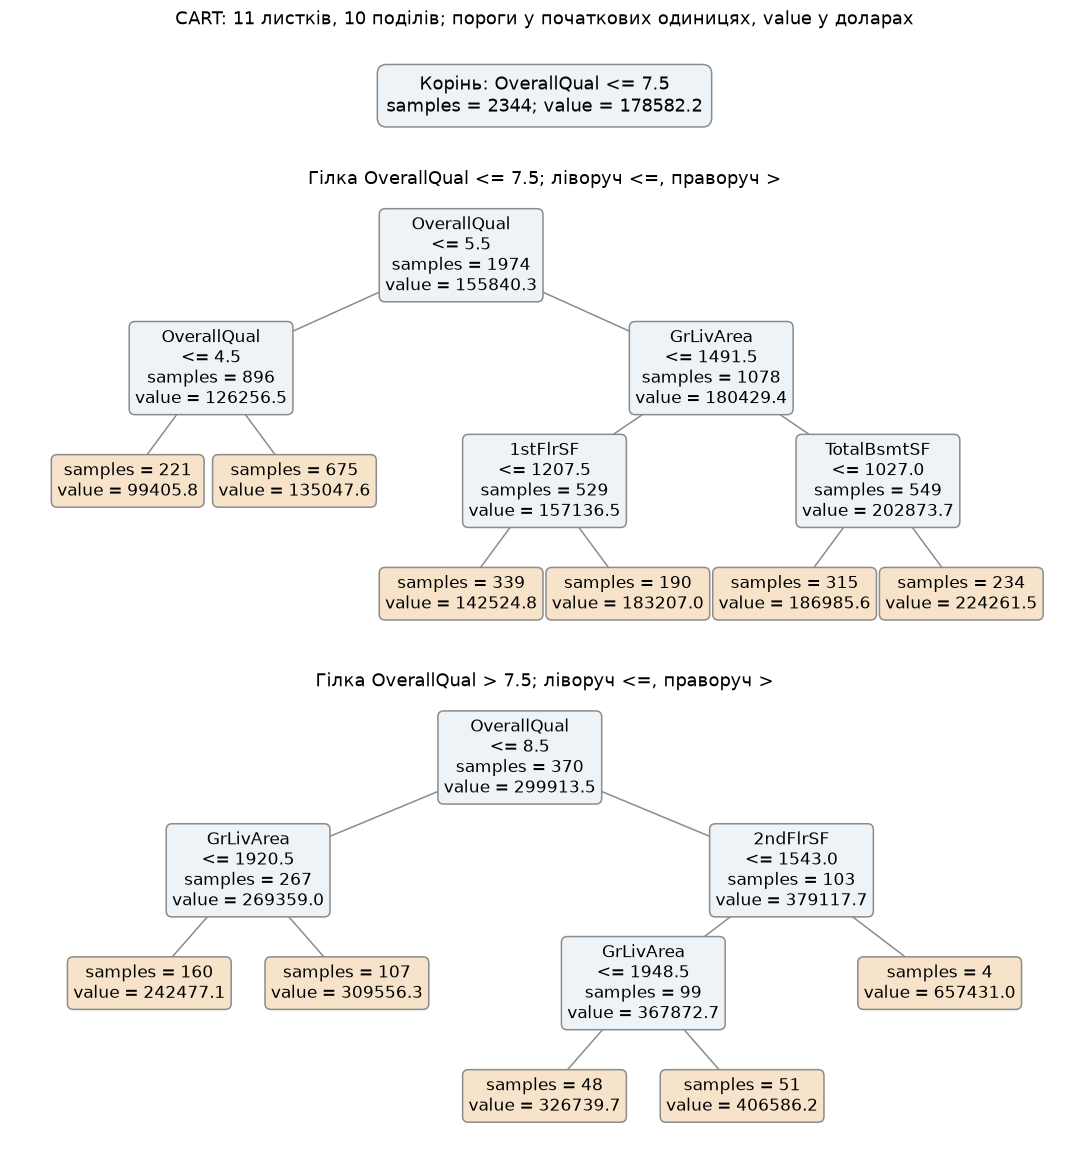

In [5]:
# ========= YOUR CODE STARTS HERE ========= #
tree = DecisionTreeRegressor(max_leaf_nodes=11, random_state=SEED)
tree.fit(Z_train, y_train)
structure = pd.Series({
    "Листків": tree.get_n_leaves(), "Поділів": tree.tree_.node_count - tree.get_n_leaves(),
    "Глибина": tree.get_depth(),
    "Навчальна MSE, дол.^2": mean_squared_error(y_train, tree.predict(Z_train)),
    "Валідаційна MSE, дол.^2": mean_squared_error(y_valid, tree.predict(Z_valid)),
})
display(structure.to_frame("Значення"))
# Для читабельних порогів повертаємо числові ознаки у початкові одиниці.
from copy import deepcopy
shown_tree = deepcopy(tree)
scaler = prepared.named_transformers_["num"].named_steps["scale"]
for node, feature in enumerate(shown_tree.tree_.feature):
    if 0 <= feature < len(numeric_columns):
        shown_tree.tree_.threshold[node] = tree.tree_.threshold[node] * scaler.scale_[feature] + scaler.mean_[feature]
# Вертикальні панелі зберігають усі вузли та читабельні підписи у PDF.
def draw_branch(ax, root):
    positions = {}
    leaves = []

    def place(node, depth):
        left = shown_tree.tree_.children_left[node]
        right = shown_tree.tree_.children_right[node]
        if left < 0:
            x = len(leaves)
            leaves.append(node)
        else:
            x = (place(left, depth + 1) + place(right, depth + 1)) / 2
        positions[node] = (x, depth)
        return x

    place(root, 0)
    depth_max = max(depth for x, depth in positions.values())
    for node, (x, depth) in positions.items():
        left = shown_tree.tree_.children_left[node]
        feature = shown_tree.tree_.feature[node]
        label = ""
        if left >= 0:
            label = f"{feature_names[feature]}\n<= {shown_tree.tree_.threshold[node]:.1f}\n"
            for child in [left, shown_tree.tree_.children_right[node]]:
                cx, cd = positions[child]
                ax.plot([x, cx], [-depth, -cd], color="0.55", linewidth=1, zorder=1)
        label += f"samples = {shown_tree.tree_.n_node_samples[node]}\n"
        label += f"value = {shown_tree.tree_.value[node, 0, 0]:.1f}"
        ax.text(x, -depth, label, ha="center", va="center", fontsize=11,
                bbox=dict(boxstyle="round,pad=0.35", facecolor="#edf3f7" if left >= 0 else "#f7e3ca",
                          edgecolor="0.55"), zorder=2)
    ax.set(xlim=(-0.7, max(1, len(leaves) - 1) + 0.7), ylim=(-depth_max - 0.55, 0.55))
    ax.axis("off")

fig, axes = plt.subplots(3, 1, figsize=(10, 10.8), gridspec_kw={"height_ratios": [1, 4, 4]})
root_feature = feature_names[shown_tree.tree_.feature[0]]
root_threshold = shown_tree.tree_.threshold[0]
axes[0].text(0.5, 0.5,
             f"Корінь: {root_feature} <= {root_threshold:.1f}\n"
             f"samples = {shown_tree.tree_.n_node_samples[0]}; value = {shown_tree.tree_.value[0, 0, 0]:.1f}",
             ha="center", va="center", fontsize=12,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="#edf3f7", edgecolor="0.55"))
axes[0].axis("off")
for ax, node, sign in zip(axes[1:], [shown_tree.tree_.children_left[0], shown_tree.tree_.children_right[0]], ["<=", ">"]):
    draw_branch(ax, node)
    ax.set_title(f"Гілка {root_feature} {sign} {root_threshold:.1f}; ліворуч <=, праворуч >", fontsize=12)
fig.suptitle("CART: 11 листків, 10 поділів; пороги у початкових одиницях, value у доларах", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part2_cart.png")
plt.show()
assert tree.get_n_leaves() <= 11
assert tree.tree_.node_count - tree.get_n_leaves() <= 10

***Answer***

`max_leaf_nodes=11` обмежує дерево одинадцятьма листками. Кожен бінарний поділ замінює один листок двома, тому кількість поділів дорівнює кількості листків мінус один. Числовий вивід і схема показують фактичний розмір дерева та його помилки.

Це обмеження росту під час навчання. На кожному кроці розщеплюється доступний листок із найбільшим покращенням критерію. Подальше обрізання через `ccp_alpha` розглядаємо в наступному пункті. На рисунку `samples` означає кількість навчальних будинків, а `value` середню ціну у вузлі.

Отримано 11 листків, 10 поділів і глибину 4. Навчальна MSE становить приблизно $1.368\cdot10^9$, валідаційна $1.589\cdot10^9$ дол.². Обмеження листків виконано; воно не гарантує, що саме цей розмір є найкращим.

### (д)

Знайдіть значення параметра складності (Cost-Complexity Pruning alpha, ccp_alpha) за допомогою методу cost_complexity_pruning_path() для дерева, навченого в попередньому пункті. Що це за параметр і що він регулює? Що станеться з архітектурою дерева, якщо ми суттєво збільшимо або зменшимо ccp_alpha? Перевірте це експериментально на ваших даних.

Прогноз: зі зростанням ccp_alpha кількість листків не збільшується.


,ccp_alpha,Листків,Глибина,"Навчальна MSE, дол.^2","Валідаційна MSE, дол.^2",Зважена неоднорідність шляху
0,0,11,4,1.36773e+09,1.58884e+09,1.36773e+09
1,6.7256e+07,10,4,1.43499e+09,1.73846e+09,1.43499e+09
2,7.9589e+07,9,4,1.51458e+09,1.83625e+09,1.51458e+09
3,8.59704e+07,8,3,1.60055e+09,1.93902e+09,1.60055e+09
4,9.023e+07,7,3,1.69078e+09,2.01528e+09,1.69078e+09
5,1.23087e+08,6,3,1.81386e+09,2.21125e+09,1.81386e+09
6,1.37522e+08,5,3,1.95139e+09,2.27441e+09,1.95139e+09
7,2.40431e+08,4,2,2.19182e+09,2.60159e+09,2.19182e+09
8,3.82003e+08,3,2,2.57382e+09,3.33575e+09,2.57382e+09
9,6.12612e+08,2,1,3.18643e+09,4.08078e+09,3.18643e+09


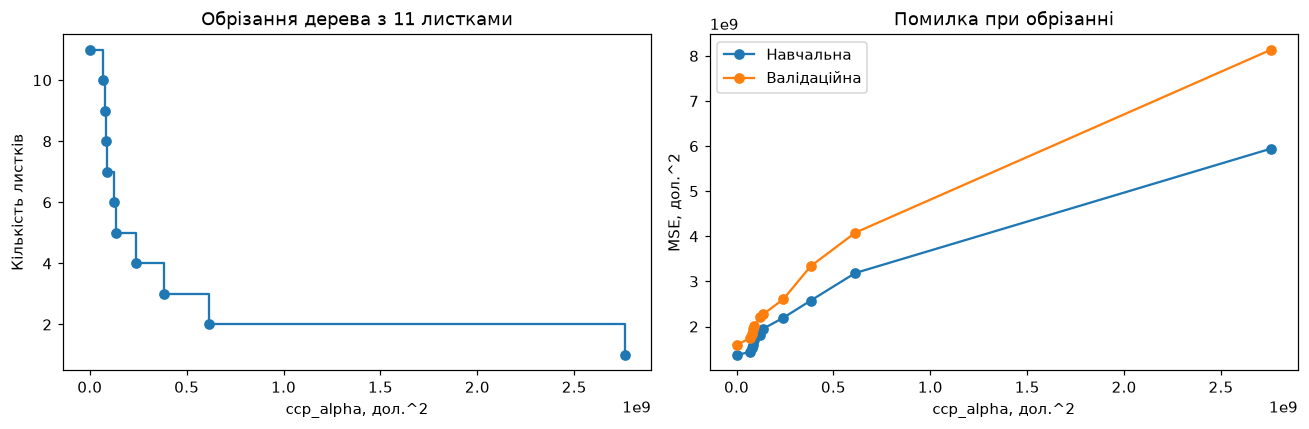

In [6]:
# ========= YOUR CODE STARTS HERE ========= #
# Прогноз: збільшення штрафу зменшить дерево; за дуже великого лишиться один листок.
print("Прогноз: зі зростанням ccp_alpha кількість листків не збільшується.")
pruning_path = tree.cost_complexity_pruning_path(Z_train, y_train)
pruning_rows = []
for alpha in pruning_path.ccp_alphas:
    model = clone(tree).set_params(ccp_alpha=float(alpha)).fit(Z_train, y_train)
    pruning_rows.append({
        "ccp_alpha": alpha, "Листків": model.get_n_leaves(), "Глибина": model.get_depth(),
        "Навчальна MSE, дол.^2": mean_squared_error(y_train, model.predict(Z_train)),
        "Валідаційна MSE, дол.^2": mean_squared_error(y_valid, model.predict(Z_valid)),
    })
pruning_table = pd.DataFrame(pruning_rows)
pruning_table["Зважена неоднорідність шляху"] = pruning_path.impurities
display(pruning_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].step(pruning_table.ccp_alpha, pruning_table["Листків"], where="post", marker="o")
axes[0].set(xlabel="ccp_alpha, дол.^2", ylabel="Кількість листків", title="Обрізання дерева з 11 листками")
for column, label in [("Навчальна MSE, дол.^2", "Навчальна"), ("Валідаційна MSE, дол.^2", "Валідаційна")]:
    axes[1].plot(pruning_table.ccp_alpha, pruning_table[column], marker="o", label=label)
axes[1].set(xlabel="ccp_alpha, дол.^2", ylabel="MSE, дол.^2", title="Помилка при обрізанні")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part2_pruning.png")
plt.show()
assert np.all(np.diff(pruning_table["Листків"]) <= 0)
assert pruning_table["Листків"].iloc[-1] == 1
assert np.allclose(pruning_path.impurities, pruning_table["Навчальна MSE, дол.^2"])

***Answer***

Метод `cost_complexity_pruning_path()` дає послідовність критичних штрафів, за яких видаляються гілки. Це набір кандидатів, а не автоматичний вибір оптимального штрафу.

У scikit-learn мінімізується $R_\alpha(T)=R(T)+\alpha|T|$, де $T$ є деревом, $|T|$ кількістю листків, $\alpha$ параметром `ccp_alpha`, а $R(T)$ сумою зважених неоднорідностей листків. Для критерію `squared_error` без ваг $R(T)=RSS(T)/n$, де $RSS(T)$ сума квадратів навчальних залишків, $n$ кількість навчальних будинків. Тому `ccp_alpha` має шкалу дол.²; у формулі зі звичайною сумою RSS штраф потрібно помножити на $n$.

За нульового штрафу залишається початкове дерево, обмежене одинадцятьма листками. Збільшення штрафу послідовно прибирає гілки; останній кандидат залишає лише корінь, що прогнозує навчальне середнє ціни. Зменшення штрафу повертає більш детальне дерево, але не скасовує обмеження `max_leaf_nodes=11`. Навчальна помилка при обрізанні не зменшується; поведінку валідаційної перевіряємо за таблицею.

**Результати після обчислень**

За нульового штрафу дерево мало 11 листків і глибину 4. Перший додатний поріг, приблизно $6.726\cdot10^7$, зменшив кількість листків до 10. За штрафу близько $2.759\cdot10^9$ залишився один листок, а глибина стала 0. На перевірених значеннях валідаційна MSE зростала, тому додаткове обрізання не покращило прогноз на цій валідаційній вибірці.


### (е)

Перевірте значення покращення (improvement / зменшення критерію неоднорідності) у першому розщепленні дерева. Поясніть концепцію інформаційного прибутку (impurity reduction) та наведіть числовий вираз, за яким воно обчислюється в scikit-learn для першого вузла.

In [7]:
# ========= YOUR CODE STARTS HERE ========= #
t = tree.tree_
left, right = t.children_left[0], t.children_right[0]
N, NL, NR = t.weighted_n_node_samples[[0, left, right]]
I, IL, IR = t.impurity[[0, left, right]]
improvement = I - NL / N * IL - NR / N * IR
root_feature = feature_names[t.feature[0]]
root_threshold = shown_tree.tree_.threshold[0]
print(f"Кореневий поділ: {root_feature} <= {root_threshold:.6g}")
display(pd.DataFrame({"Вузол": ["Корінь", "Лівий", "Правий"],
                      "Кількість": [N, NL, NR], "MSE, дол.^2": [I, IL, IR]}))
print(f"Покращення = {I:.6f} - ({NL:.0f}/{N:.0f}) * {IL:.6f} - ({NR:.0f}/{N:.0f}) * {IR:.6f} = {improvement:.6f} дол.^2")
print("Зменшення RSS, дол.^2:", N * improvement)
# Незалежна перевірка без використання збережених impurity дочірніх вузлів.
mask = Z_train[:, t.feature[0]] <= t.threshold[0]
root_rss = np.sum((y_train - y_train.mean()) ** 2)
children_rss = sum(np.sum((group - group.mean()) ** 2) for group in [y_train[mask], y_train[~mask]])
assert np.isclose(N * improvement, root_rss - children_rss)
assert mask.sum() == NL

Кореневий поділ: OverallQual <= 7.5


,Вузол,Кількість,"MSE, дол.^2"
0,Корінь,2344,5.94574e+09
1,Лівий,1974,2.29321e+09
2,Правий,370,7.95189e+09


Покращення = 5945739180.175694 - (1974/2344) * 2293210777.136368 - (370/2344) * 7951889620.865341 = 2759306913.201561 дол.^2
Зменшення RSS, дол.^2: 6467815404544.459


***Answer***

Інформаційний прибуток у корені показує, наскільки після поділу зменшується середній квадрат відхилень цін від середнього свого вузла. Від MSE кореня віднімаємо зважену MSE дочірніх вузлів.
$$\Delta=I-\frac{N_L}{N}I_L-\frac{N_R}{N}I_R.$$
Тут $\Delta$ є покращенням, $I$, $I_L$ та $I_R$ є MSE кореня, лівого й правого вузлів, а $N$, $N_L$ та $N_R$ позначають кількість навчальних будинків у цих вузлах.

У корені обрано поділ `OverallQual ≤ 7.5` у початковій шкалі. Підставляємо значення зі збереженого виводу.
$$\Delta\approx\left(5.94574-\frac{1974}{2344}\cdot2.29321-\frac{370}{2344}\cdot7.95189\right)\cdot10^9\approx2.7593\cdot10^9\ \text{дол.}^2.$$
MSE правого вузла вища за MSE кореня. Проте в ньому лише 370 із 2344 будинків, і зважена MSE двох дочірніх вузлів після поділу зменшилася.


### (ж)

Обчисліть важливість ознак (feature_importances_) для дерева регресії та порівняйте топ-10 результатів із коефіцієнтами, отриманими в регресії ласо та класичній лінійній регресії.

In [8]:
# ========= YOUR CODE STARTS HERE ========= #
# Відтворюємо фінальні Lasso та OLS частини (1), не читаючи її стан ядра.
lasso_search = GridSearchCV(
    Pipeline([("prepare", clone(preprocessor)), ("model", Lasso(max_iter=50000, tol=1e-6))]),
    {"model__alpha": np.logspace(1, 4, 35)},
    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
    scoring="neg_mean_squared_error", n_jobs=1,
).fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_.named_steps["model"]
ols_model = LinearRegression().fit(Z_train, y_train)
print("Обраний alpha Lasso:", lasso_model.alpha)
print("Ненульових коефіцієнтів Lasso:", np.count_nonzero(lasso_model.coef_))
print("Ранг OLS / ознак:", ols_model.rank_, "/", Z_train.shape[1])
importance = pd.DataFrame({"Lasso, коеф.": lasso_model.coef_, "OLS, коеф.": ols_model.coef_,
                           "CART MDI": tree.feature_importances_},
                          index=pd.Index(feature_names, name="Ознака"))
tree_top10 = importance.sort_values("CART MDI", ascending=False, kind="stable").head(10)
display(tree_top10)
print("Кількість ознак із додатною CART MDI:", (importance["CART MDI"] > 0).sum())
# Додатково перевіряємо, що саме кожна лінійна модель ставить у свій топ-10.
display(pd.DataFrame({
    "CART MDI": importance["CART MDI"].sort_values(ascending=False, kind="stable").head(10).index,
    "Lasso за модулем": importance["Lasso, коеф."].abs().sort_values(ascending=False).head(10).index,
    "OLS за модулем": importance["OLS, коеф."].abs().sort_values(ascending=False).head(10).index,
}))
# Перевіряємо MDI через зважені зменшення неоднорідності всіх поділів.
manual_mdi = np.zeros(Z_train.shape[1])
for node, feature in enumerate(t.feature):
    if feature >= 0:
        l, r = t.children_left[node], t.children_right[node]
        manual_mdi[feature] += (t.weighted_n_node_samples[node] * t.impurity[node]
                               - t.weighted_n_node_samples[l] * t.impurity[l]
                               - t.weighted_n_node_samples[r] * t.impurity[r])
manual_mdi /= manual_mdi.sum()
assert np.allclose(manual_mdi, tree.feature_importances_)
assert np.allclose(lasso_search.best_estimator_.named_steps["prepare"].transform(X_train), Z_train)
assert lasso_model.n_iter_ < lasso_model.max_iter

Обраний alpha Lasso: 76.26985859023443
Ненульових коефіцієнтів Lasso: 126
Ранг OLS / ознак: 280 / 294


,"Lasso, коеф.","OLS, коеф.",CART MDI
Ознака,,,
OverallQual,14157.1,8711.49,0.8397
GrLivArea,23057.6,16429.2,0.0940963
2ndFlrSF,4383.1,13632.9,0.0300397
1stFlrSF,0,6470.09,0.018779
TotalBsmtSF,4197.38,9661.19,0.0173851
LotFrontage,-1624.16,1350.95,0
LotArea,3303.43,5462.63,0
OverallCond,6306.27,6698.35,0
YearBuilt,9510.14,12549.5,0


Кількість ознак із додатною CART MDI: 5


,CART MDI,Lasso за модулем,OLS за модулем
0,OverallQual,PoolQC_Gd,RoofMatl_Membran
1,GrLivArea,MiscFeature_Gar2,RoofMatl_WdShngl
2,2ndFlrSF,RoofMatl_WdShngl,RoofMatl_Metal
3,1stFlrSF,Neighborhood_StoneBr,RoofMatl_Roll
4,TotalBsmtSF,Neighborhood_NoRidge,RoofMatl_WdShake
5,LotFrontage,Neighborhood_NridgHt,RoofMatl_CompShg
6,LotArea,KitchenQual_TA,RoofMatl_Tar&Grv
7,OverallCond,Neighborhood_GrnHill,MiscFeature_Othr
8,YearBuilt,KitchenQual_Gd,MiscFeature_Gar2
9,YearRemodAdd,GrLivArea,MiscFeature_Shed


***Answer***

MDI підсумовує зважене зменшення неоднорідності в усіх поділах за ознакою та нормує внески так, щоб їхня сума дорівнювала одиниці. У таблиці зіставляємо MDI десяти ознак дерева з коефіцієнтами тих самих ознак у Lasso й МНК. MDI безрозмірна й показує внесок у поділи. Знак коефіцієнта показує напрям зміни прогнозу лінійної моделі за незмінних інших ознак.

Лише п’ять ознак мають додатну MDI. Решта рядків топ-10 мають нульову MDI нарівні з іншими невикористаними ознаками. Найвищі MDI у `OverallQual` (0.8397) та `GrLivArea` (0.09410), і для обох коефіцієнти Lasso й МНК додатні. Дерево використало `1stFlrSF`, а Lasso оцінило її коефіцієнт нулем.

### (з)

(опціонально) Застосуйте техніку бутстрепу (bootstrap) для оцінки розподілу параметрів у лінійній регресії. Розгляньте лише перші 10 числових ознак. Створіть цикл на 1000 ітерацій: у кожній ітерації згенеруйте бутстреп-вибірку за допомогою df.sample(replace=True), оцініть коефіцієнти через LinearRegression і збережіть значення для LotArea та Street. Побудуйте графік у вигляді гістограми або KDE (оцінку щільності ядра) через seaborn.kdeplot для цих двох параметрів. Порівняйте їх із теоретичним нормальним розподілом МНК (де дисперсія береться з діагоналі коваріаційної матриці залишків $\hat{\sigma}^{2}(X'X)^{-1}$).

In [ ]:
# Опціональний пункт. Залишено невиконаним.
# ========= YOUR CODE STARTS HERE ========= #


***Answer***

Опціональний пункт. Не виконано.

### (и)

(опціонально) Використовуючи отриманий бутстреп-розподіл коефіцієнтів, обчисліть 95% довірчий інтервал через квантилі (np.percentile на рівнях 2.5% та 97.5%). Порівняйте їх із класичними довірчими інтервалами, що базуються на припущенні про нормальність залишків (які можна отримати через summary().tables в statsmodels).

In [ ]:
# Опціональний пункт. Залишено невиконаним.
# ========= YOUR CODE STARTS HERE ========= #


***Answer***

Опціональний пункт. Не виконано.

### (і)

Використовуйте беггінг (BaggingRegressor) та випадковий ліс (RandomForestRegressor) для прогнозування SalePrice. Побудуйте графік залежності середньоквадратичної помилки (MSE) на навчальній та валідаційній вибірках від кількості базових дерев (n_estimators). Прокоментуйте поведінку обох кривих на графіку.

Прогноз: зі збільшенням ансамблю валідаційна MSE стабілізуватиметься; монотонність не гарантована.


,Модель,Дерев,"Навчальна MSE, дол.^2","Валідаційна MSE, дол.^2"
0,Bagging,1,6.53192e+08,1.53168e+09
1,Bagging,5,2.05021e+08,8.4875e+08
2,Bagging,10,1.68949e+08,7.66191e+08
3,Bagging,25,1.22267e+08,7.41785e+08
4,Bagging,50,1.07443e+08,7.22265e+08
5,Bagging,100,1.00961e+08,7.05429e+08
6,Bagging,200,9.85243e+07,7.0914e+08
7,Random Forest,1,6.40523e+08,2.56631e+09
8,Random Forest,5,2.00007e+08,9.50028e+08
9,Random Forest,10,1.50852e+08,8.11277e+08


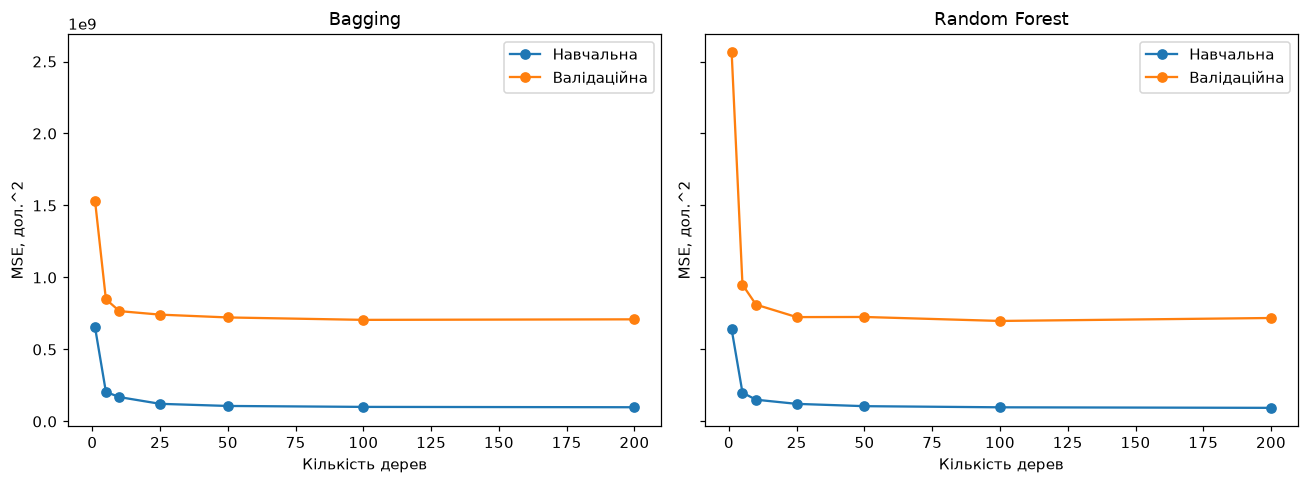

,Модель,Початок плато на сітці,"MSE при 200 деревах, дол.^2"
0,Bagging,100,7.0914e+08
1,Random Forest,25,7.18452e+08


In [9]:
# ========= YOUR CODE STARTS HERE ========= #
# Прогноз до досліду: усереднення зменшить коливання прогнозів; криві можуть мати нерівності.
print("Прогноз: зі збільшенням ансамблю валідаційна MSE стабілізуватиметься; монотонність не гарантована.")
ensemble_sizes = [1, 5, 10, 25, 50, 100, FINAL_TREES]
ensembles = {
    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=SEED),
        bootstrap=True, max_samples=1.0, max_features=1.0,
        warm_start=True, random_state=SEED, n_jobs=1),
    "Random Forest": RandomForestRegressor(
        bootstrap=True, max_features=1/3, warm_start=True,
        random_state=SEED, n_jobs=1),
}
curve_rows = []
for name, model in ensembles.items():
    for size in ensemble_sizes:
        # Нові дерева додаються до того самого ансамблю; старі залишаються.
        model.set_params(n_estimators=size).fit(Z_train, y_train)
        curve_rows.append({"Модель": name, "Дерев": size,
                           "Навчальна MSE, дол.^2": mean_squared_error(y_train, model.predict(Z_train)),
                           "Валідаційна MSE, дол.^2": mean_squared_error(y_valid, model.predict(Z_valid))})
curves = pd.DataFrame(curve_rows)
display(curves)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, group) in zip(axes, curves.groupby("Модель", sort=False)):
    ax.plot(group["Дерев"], group["Навчальна MSE, дол.^2"], "o-", label="Навчальна")
    ax.plot(group["Дерев"], group["Валідаційна MSE, дол.^2"], "o-", label="Валідаційна")
    ax.set(xlabel="Кількість дерев", ylabel="MSE, дол.^2", title=name)
    ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part2_ensemble_mse.png")
plt.show()
# Описовий критерій плато: не більш ніж на 1% вище MSE при 200 деревах.
plateau_rows = []
for name, group in curves.groupby("Модель", sort=False):
    mse = group["Валідаційна MSE, дол.^2"].to_numpy()
    acceptable = np.array([np.all(mse[i:] <= 1.01 * mse[-1]) for i in range(len(mse))])
    plateau_rows.append({"Модель": name, "Початок плато на сітці": group["Дерев"].to_numpy()[acceptable][0],
                         "MSE при 200 деревах, дол.^2": mse[-1]})
display(pd.DataFrame(plateau_rows))

***Answer***

Обидва ансамблі усереднюють прогнози дерев, навчених на вибірках із поверненням. У випадковому лісі кожен вузол розглядає випадкову підмножину ознак, тому дерева можуть давати менш схожі прогнози.

Початком плато називаємо найменшу перевірену кількість дерев, від якої всі показані валідаційні MSE не більш ніж на 1% перевищують MSE цієї моделі при 200 деревах.

Навчальна MSE спадала на всій перевіреній сітці в обох моделей і залишалася нижчою за валідаційну. Валідаційна MSE найбільше впала від 1 до 5 дерев. В обох моделей вона була найменшою при 100 деревах і трохи зросла при 200. За критерієм 1% плато починається зі 100 дерев для беггінгу і з 25 для випадкового лісу. При 200 деревах валідаційна MSE становить $7.0914\cdot10^8$ дол.² для беггінгу та $7.1845\cdot10^8$ дол.² для лісу.

### (к)

Порівняйте час виконання (time.time()) обох ансамблевих підходів. Чому випадковий ліс зазвичай обчислювально швидший і потребує менше дерев порівняно з чистим беггінгом над глибокими деревами? Перевірте вбудований метод розрахунку важливості ознак для RandomForestRegressor (MDI або permutation importance). Зробіть фінальну порівняльну таблицю важливостей змінних для всіх моделей: Lasso, OLS, одиночне дерево та Random Forest.

Прогноз: Random Forest із max_features=1/3 швидший за беггінг з усіма ознаками.


,Повтор,Модель,"Час навчання, с"
0,1,Bagging,5.72391
1,1,Random Forest,2.11956
2,2,Random Forest,2.10959
3,2,Bagging,5.63344
4,3,Bagging,5.63201
5,3,Random Forest,2.12593


,median,min,max
Модель,,,
Bagging,5.63344,5.63201,5.72391
Random Forest,2.11956,2.10959,2.12593


Відношення медіанного часу Bagging / Random Forest: 2.6578315085294992
Максимальна абсолютна різниця з MDI лісу: 0.0


,"Lasso, коеф.","OLS, коеф.",CART MDI,Random Forest MDI
Ознака,,,,
OverallQual,14157.1,8711.49,0.8397,0.286514
GrLivArea,23057.6,16429.2,0.0940963,0.104882
GarageCars,6388.78,3417.26,0,0.101298
YearBuilt,9510.14,12549.5,0,0.0718618
TotalBsmtSF,4197.38,9661.19,0.0173851,0.0483594
ExterQual_TA,-10256,-18206.5,0,0.0451815
GarageArea,589.571,2437.46,0,0.04317
1stFlrSF,0,6470.09,0.018779,0.0391335
2ndFlrSF,4383.1,13632.9,0.0300397,0.0225395


Суми MDI: {'CART MDI': 0.9999999999999998, 'Random Forest MDI': 0.9999999999999999}


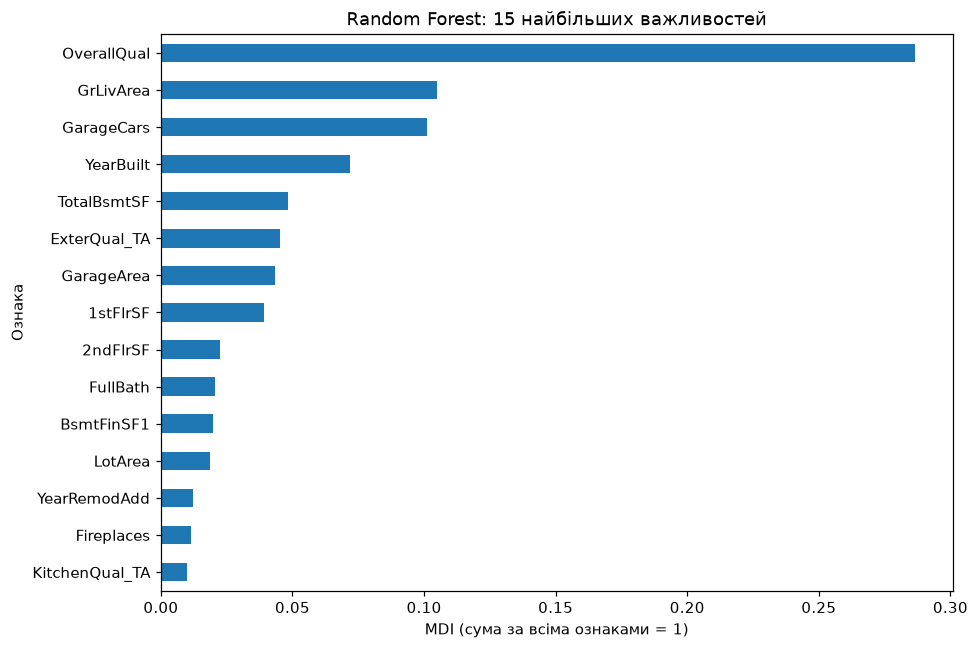

***Answer***

У цьому запуску медіанний час навчання становить 5.633 с для беггінгу та 2.120 с для випадкового лісу. Ліс швидший приблизно у 2.66 раза. Це підтверджує початкове очікування для заданих налаштувань.

In [10]:
# ========= YOUR CODE STARTS HERE ========= #
# Прогноз: ліс із третиною ознак має навчатися швидше; перевіряємо фактичний час.
print("Прогноз: Random Forest із max_features=1/3 швидший за беггінг з усіма ознаками.")
timing_rows = []
for repeat in range(3):
    # Чергуємо порядок, щоб один метод не завжди виконувався першим.
    names = list(ensembles) if repeat % 2 == 0 else list(reversed(ensembles))
    for name in names:
        model = clone(ensembles[name]).set_params(warm_start=False, n_estimators=FINAL_TREES)
        start = time.time()
        model.fit(Z_train, y_train)
        elapsed = time.time() - start
        timing_rows.append({"Повтор": repeat + 1, "Модель": name, "Час навчання, с": elapsed})
        # Незалежне навчання з нуля відтворює ансамбль, нарощений у (і).
        assert np.allclose(model.predict(Z_valid), ensembles[name].predict(Z_valid))
timings = pd.DataFrame(timing_rows)
display(timings)
timing_summary = timings.groupby("Модель")["Час навчання, с"].agg(["median", "min", "max"])
display(timing_summary)
print("Відношення медіанного часу Bagging / Random Forest:",
      timing_summary.loc["Bagging", "median"] / timing_summary.loc["Random Forest", "median"])

forest = ensembles["Random Forest"]
importance["Random Forest MDI"] = forest.feature_importances_
# Відтворюємо MDI лісу за нормованими важливостями окремих дерев.
forest_mdi = np.mean([
    estimator.feature_importances_
    for estimator in forest.estimators_
    if estimator.tree_.node_count > 1
], axis=0)
forest_mdi /= forest_mdi.sum()
mdi_difference = np.abs(forest_mdi - forest.feature_importances_)
np.testing.assert_allclose(forest_mdi, forest.feature_importances_)
print("Максимальна абсолютна різниця з MDI лісу:", mdi_difference.max())
# Повна таблиця зберігає знак коефіцієнтів і не змішує їх одиниці з MDI.
final_importance = importance.sort_values("Random Forest MDI", ascending=False)
display(final_importance)
print("Суми MDI:", final_importance[["CART MDI", "Random Forest MDI"]].sum().to_dict())
fig, ax = plt.subplots(figsize=(9, 6))
final_importance["Random Forest MDI"].head(15).sort_values().plot.barh(ax=ax)
ax.set(xlabel="MDI (сума за всіма ознаками = 1)", ylabel="Ознака", title="Random Forest: 15 найбільших важливостей")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part2_forest_importance.png")
plt.show()
assert np.isclose(forest.feature_importances_.sum(), 1)
assert np.isfinite(final_importance.to_numpy()).all()

# Абзац автоматично використовує час саме цього запуску.
bagging_seconds = timing_summary.loc["Bagging", "median"]
forest_seconds = timing_summary.loc["Random Forest", "median"]
time_ratio = bagging_seconds / forest_seconds
if time_ratio > 1:
    speed_result = f"Ліс швидший приблизно у {time_ratio:.2f} раза. Це підтверджує початкове очікування для заданих налаштувань."
elif time_ratio < 1:
    speed_result = f"Беггінг швидший приблизно у {1 / time_ratio:.2f} раза. Початкове очікування щодо швидкості лісу цього разу не підтвердилося."
else:
    speed_result = "Медіанний час однаковий; переваги лісу за швидкістю не спостерігаємо."
display(Markdown(
    "***Answer***" + chr(10) * 2
    + f"У цьому запуску медіанний час навчання становить {bagging_seconds:.3f} с для беггінгу "
    + f"та {forest_seconds:.3f} с для випадкового лісу. " + speed_result
))


***Answer***

Через `time.time()` вимірюємо час навчання з нуля. Для обох методів використовуємо 200 глибоких дерев, ті самі дані й один потік. Порівнюємо медіани трьох повторів із чергуванням порядку.

Беггінг розглядає всі ознаки у вузлі, а ліс із `max_features=1/3` зазвичай перевіряє менше кандидатів, тому кожен поділ можна знайти швидше. Випадковий вибір ознак також зменшує подібність дерев. Усереднення менш схожих прогнозів може стабілізувати помилку за меншої кількості дерев.

Щоб перевірити MDI лісу, усереднюємо важливості дерев із поділами, нормуємо їхню суму до одиниці й порівнюємо значення для кожної ознаки з `feature_importances_`. Фінальна таблиця зіставляє коефіцієнти Lasso й МНК із MDI одиночного дерева та лісу.

За критерієм 1% із 2.і ліс досяг плато раніше за беггінг, хоча при 200 деревах його валідаційна MSE трохи вища. Найвищі MDI лісу мають `OverallQual` (0.2865), `GrLivArea` (0.1049) і `GarageCars` (0.1013). Частка `OverallQual` у лісі менша, ніж в одиночному дереві, де її MDI становить 0.8397.